# Evaluate Validation Case and Compare with permaFoam Simulation Result

In [1]:

from parse_permafoam_output import parse_permafoam_output
from make_permafoam_comparison_figure import make_comparison_figure


In [2]:
permaFoam_output_folder = "/usr/lib/openfoam/openfoam2412/tutorials/hydrology-main/tutorials/permaFoam/validationCase"
save_folder = "./"
save_filename = "permaFoam_output.pkl"
fields = ("T", "psi", "thetal", "thetag", "theta")
xtot = 10.0


parse_permafoam_output(case_dir=permaFoam_output_folder, out_file=save_folder + save_filename,
                           fields=fields, xtot=xtot,
                           x_patch="top", z_patch="downSlope", verbose=True)

inferred mesh: 50 x 200 cells, geometry from t=2628000
saved: permaFoam_output.pkl
0 fields: ['T', 'psi', 'thetal', 'thetag', 'theta', 'T_C']
657000 fields: ['T', 'psi', 'thetal', 'thetag', 'theta', 'T_C']
1314000 fields: ['T', 'psi', 'thetal', 'thetag', 'theta', 'T_C']
1971000 fields: ['T', 'psi', 'thetal', 'thetag', 'theta', 'T_C']
2628000 fields: ['T', 'psi', 'thetal', 'thetag', 'theta', 'T_C']


{'X': array([[0.1, 0.3, 0.5, ..., 9.5, 9.7, 9.9],
        [0.1, 0.3, 0.5, ..., 9.5, 9.7, 9.9],
        [0.1, 0.3, 0.5, ..., 9.5, 9.7, 9.9],
        ...,
        [0.1, 0.3, 0.5, ..., 9.5, 9.7, 9.9],
        [0.1, 0.3, 0.5, ..., 9.5, 9.7, 9.9],
        [0.1, 0.3, 0.5, ..., 9.5, 9.7, 9.9]], shape=(200, 50)),
 'Z': array([[-0.0075  , -0.0275  , -0.0475  , ..., -0.947499, -0.967499,
         -0.987502],
        [-0.0025  , -0.0225  , -0.0425  , ..., -0.942503, -0.962503,
         -0.982497],
        [ 0.0025  , -0.0175  , -0.0375  , ..., -0.9375  , -0.9575  ,
         -0.977505],
        ...,
        [ 0.977499,  0.957498,  0.937498, ...,  0.0375  ,  0.0175  ,
         -0.0025  ],
        [ 0.982498,  0.962504,  0.9425  , ...,  0.0425  ,  0.0225  ,
          0.0025  ],
        [ 0.987503,  0.967503,  0.947496, ...,  0.0475  ,  0.0275  ,
          0.0075  ]], shape=(200, 50)),
 'times': [0, 657000, 1314000, 1971000, 2628000],
 'fields': {0: {'T': array([[268.15, 268.15, 268.15, ..., 268.15, 

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


saved: validation.png
saved: validation.pdf

Domain-mean T bias (ours - permaFoam), raw vs. clipped to (-4.75, 5.8):
   t [d]      raw  clipped
     7.6    0.005    0.005
    15.2    0.004    0.004
    22.8    0.006    0.006
    30.4    0.007    0.007


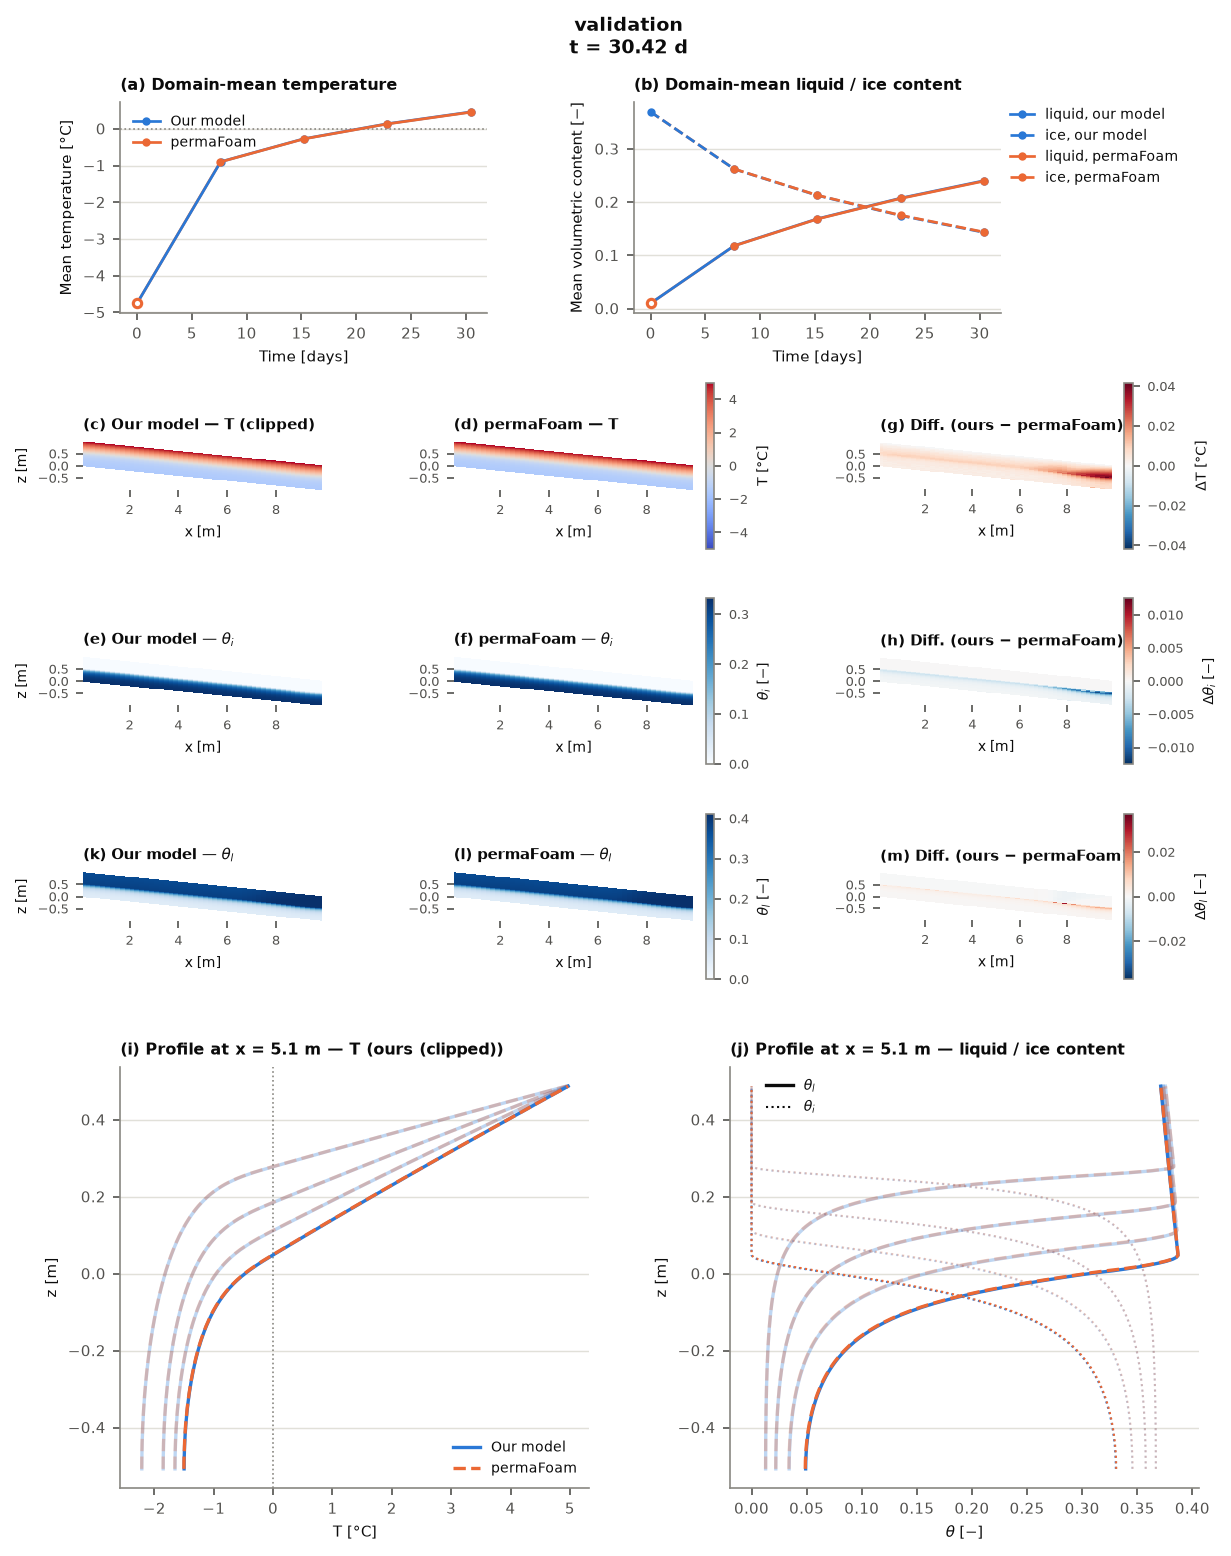

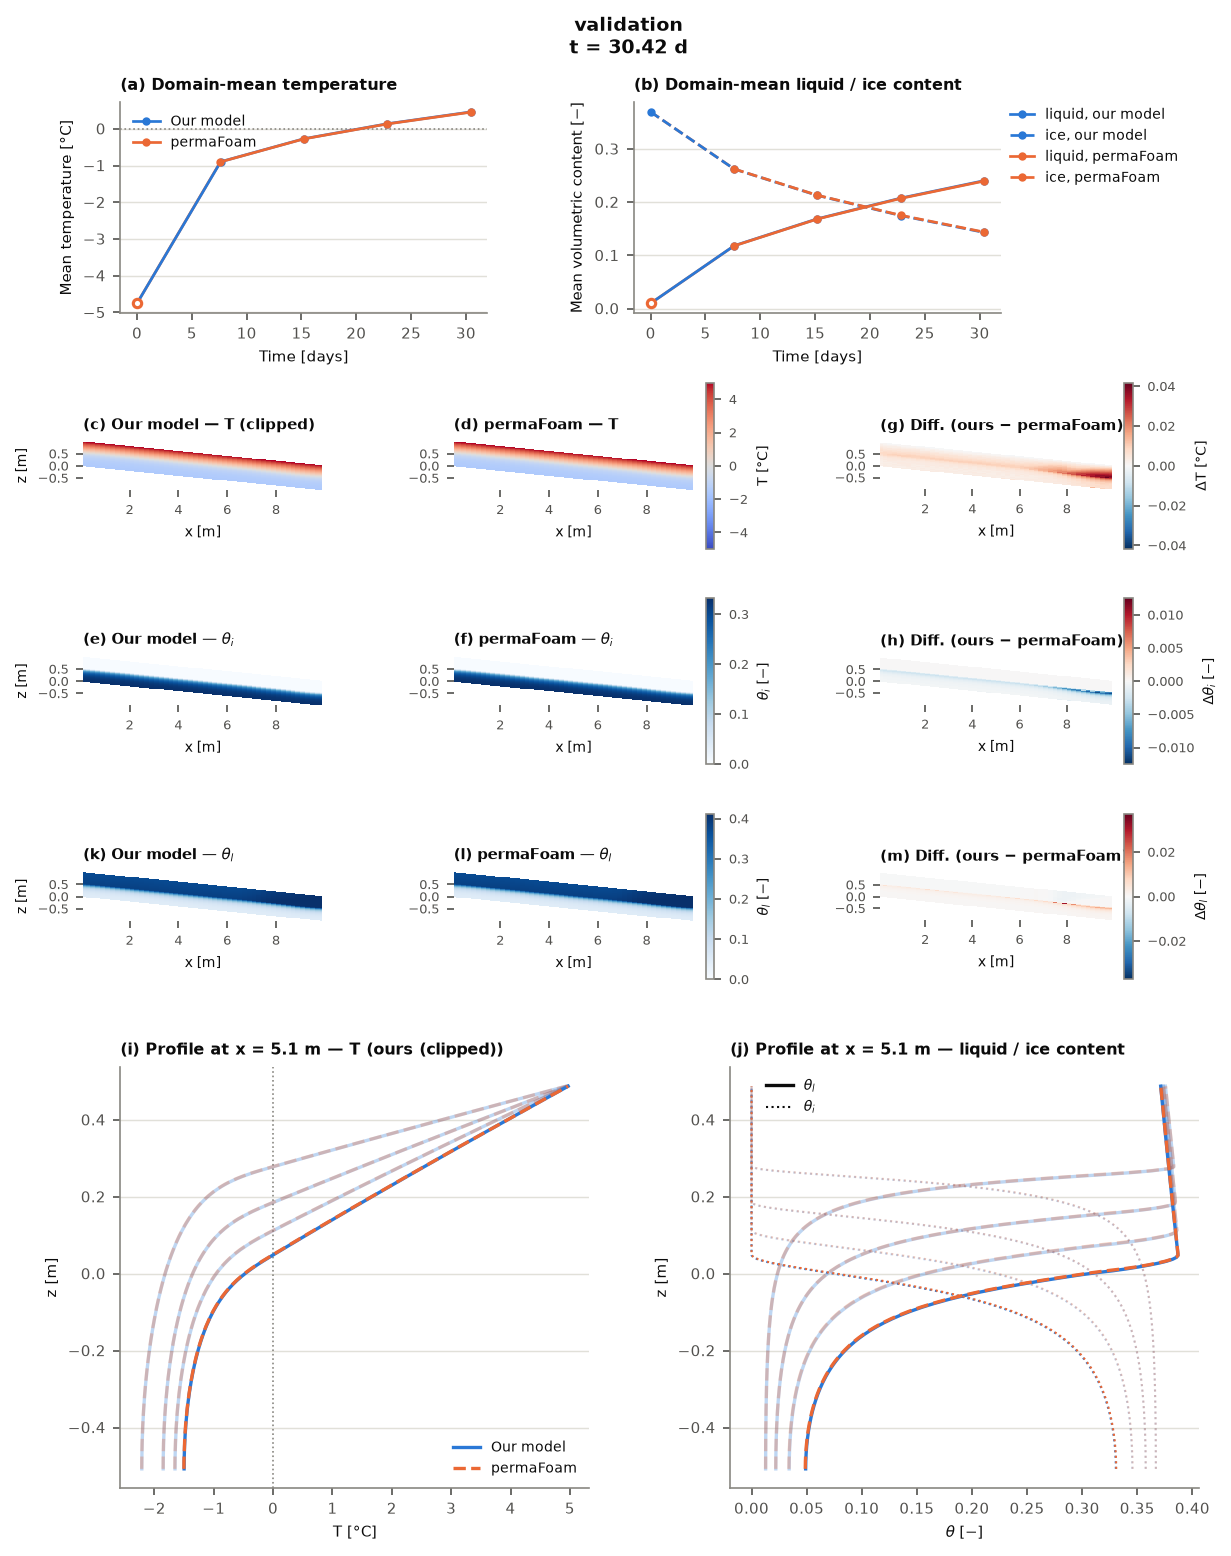

In [3]:
A4_INCHES = (210 / 25.4, 297 / 25.4)  # DIN A4 portrait

make_comparison_figure(ours_pkl="./cryorich_AD_output.pkl", pf_pkl=save_folder + save_filename,
                           checkpoint_idx=-1,
                           out_png="validation.png", out_pdf="validation.pdf",
                           t_clip=(-4.75, 5.8),
                           xlim=None, ylim=None, xticks=None, yticks=None,
                           profile_x=None,
                           title="validation", figsize=A4_INCHES,
                           print_bias=True, dpi=300)